# RetailMind AI – Customer Churn Prediction

In [1]:
import os
print(os.getcwd())
print(os.listdir())

/drive/notebooks/Reatail incremental
['Data', 'Notebooks', 'Src', 'models']


In [42]:
import os

print(os.listdir("Data"))
print(os.listdir("models"))

['Telco-Customer-Churn.csv']
['churn_pipeline.joblib']


In [43]:
import joblib

model = joblib.load("models/churn_pipeline.joblib")

print("Model loaded successfully!")
print(type(model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [2]:
import os

print("Current location:")
print(os.getcwd())

print("\nFolders and files here:")
for item in os.listdir():
    print(item)

Current location:
/drive/notebooks/Reatail incremental

Folders and files here:
Data
Notebooks
Src
models


In [3]:
from pathlib import Path

matches = list(Path("/").rglob("preprocessing.py"))

print(matches)

[PosixPath('/drive/notebooks/Reatail incremental/Src/preprocessing.py')]


In [4]:
import os

print("Current directory:", os.getcwd())
print("Available files:", os.listdir())
print("Is src folder present:", os.path.exists("src"))
print("Is preprocessing.py present:", os.path.exists("src/preprocessing.py"))

Current directory: /drive/notebooks/Reatail incremental
Available files: ['Data', 'Notebooks', 'Src', 'models']
Is src folder present: False
Is preprocessing.py present: False


In [5]:
import sys
print(sys.platform)

emscripten


In [6]:
import sys
print(sys.version)
print(sys.executable)
print(sys.platform)

3.13.1 (main, Feb 18 2026, 20:57:27) [Clang 21.0.0git (https:/github.com/llvm/llvm-project 2f05451198e2f222ec66cec489

emscripten


In [7]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.798 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [8]:
!mamba install scikit-learn joblib seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn, joblib, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.863 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ patsy               1.0.3       py313h1804a44_0      emscripten-forge-4x
+ pysocks             1.7.1       py313h1804a44_3      emscripten-f

## 1. Import Libraries

In [9]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore")

In [10]:
import os

print("Current directory:", os.getcwd())
print("Available files:", os.listdir())

Current directory: /drive/notebooks/Reatail incremental
Available files: ['Data', 'Notebooks', 'Src', 'models']


## 2. Dataset Loading

In [11]:
from pathlib import Path

files = list(Path(".").rglob("Telco-Customer-Churn.csv"))

print(files)

[PosixPath('Data/Telco-Customer-Churn.csv')]


In [12]:
import pandas as pd

if files:
    df = pd.read_csv(files[0])
    print("Dataset Shape:", df.shape)
    display(df.head())
else:
    print("CSV file not found. Please upload it to Jupyter.")

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Exploratory Data Analysis (EDA)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [14]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [15]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [17]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [18]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


## 4. Data Visualization

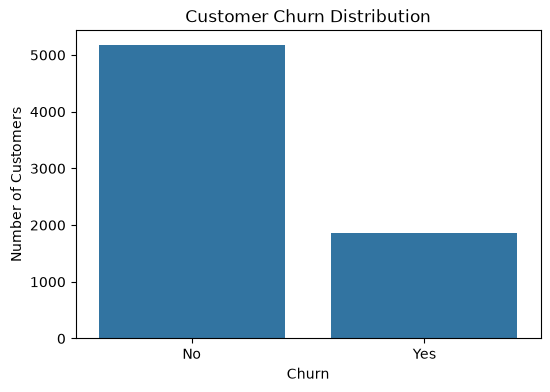

In [19]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [20]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


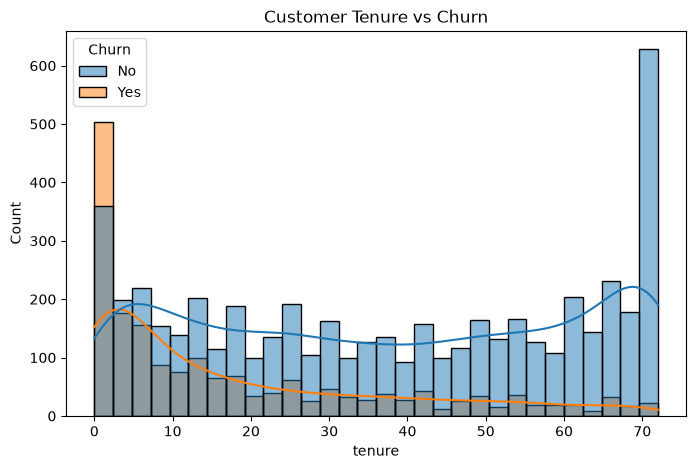

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Customer Tenure vs Churn")
plt.show()

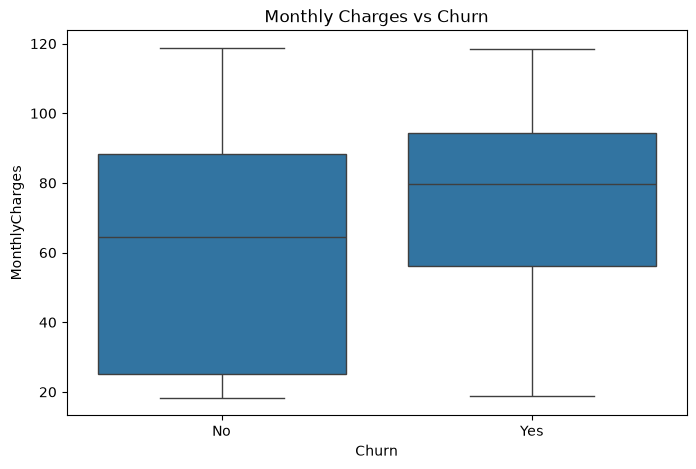

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.show()

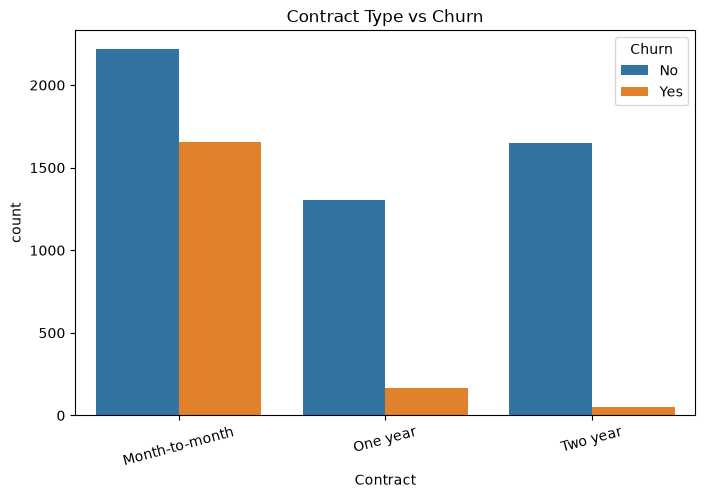

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Churn")
plt.xticks(rotation=15)
plt.show()

## 5: Data Cleaning

In [24]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working shape:", df_clean.shape)

Original shape: (7043, 21)
Working shape: (7043, 21)


In [25]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges:", df_clean["TotalCharges"].isnull().sum())

Missing TotalCharges: 11


In [26]:
df_clean.drop("customerID", axis=1, inplace=True)

print(df_clean.columns)

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


In [27]:
df_clean["Churn"] = df_clean["Churn"].map({
    "Yes": 1,
    "No": 0
})

print(df_clean["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [28]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [29]:
df_clean.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

## 6: Feature Engineering

In [30]:
X = df_clean.drop("Churn", axis=1)

y = df_clean["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 19)
Target: (7043,)


In [31]:
num_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns

cat_cols = X.select_dtypes(
    include=["object"]
).columns

print("Numerical columns:", list(num_cols))
print("Categorical columns:", list(cat_cols))

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 7: Create Preprocessing Pipeline

In [32]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [33]:
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [34]:
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


## 8: Split the Dataset

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=67,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5282, 19)
Testing data: (1761, 19)


## 9: Train Logistic Regression

In [36]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=4000,
        random_state=33
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


## 10: Evaluate the Model

In [37]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7984099943214082
Precision: 0.6365853658536585
Recall: 0.5588865096359743
ROC-AUC: 0.8388924007691568


In [38]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1294
           1       0.64      0.56      0.60       467

    accuracy                           0.80      1761
   macro avg       0.74      0.72      0.73      1761
weighted avg       0.79      0.80      0.79      1761



## 11: Confusion Matrix

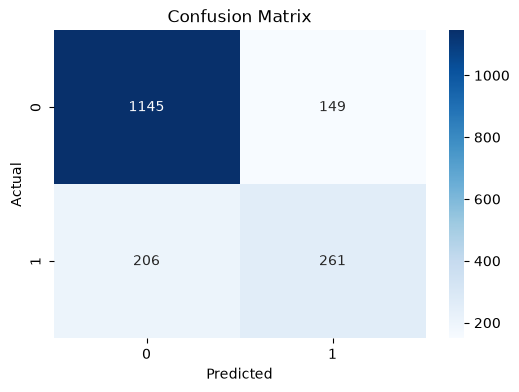

In [39]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

## 12: Save the Model

In [40]:
import os

os.makedirs("models", exist_ok=True)

joblib.dump(model, "models/churn_pipeline.joblib")

print("Model saved successfully!")

Model saved successfully!
